In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data_dir = Path("../data")
processed_dir = data_dir / "processed"
figure_dir = Path("../reports/figures")

figure_dir.mkdir(
    parents=True,
    exist_ok=True
)

print("Processed:", processed_dir.resolve())
print("Figures:", figure_dir.resolve())

Processed: C:\kirc-genomic-prognosis\data\processed
Figures: C:\kirc-genomic-prognosis\reports\figures


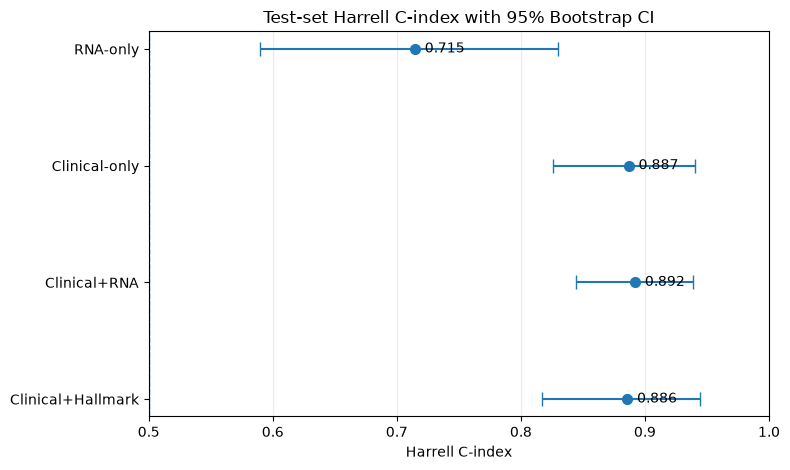

Saved: ..\reports\figures\fig1_test_harrell_cindex_ci.png


In [2]:
# ============================================================
# Figure 1 — Test Harrell C-index with 95% Bootstrap CI
# ============================================================

perf = pd.read_csv(
    processed_dir / "final_performance_summary.csv"
)

model_order = [
    "RNA-only",
    "Clinical-only",
    "Clinical+RNA",
    "Clinical+Hallmark",
]

perf = (
    perf
    .set_index("model")
    .loc[model_order]
    .reset_index()
)

cindex = perf["test_harrell_c"].to_numpy()

lower_error = (
    cindex
    - perf["ci_95_lower"].to_numpy()
)

upper_error = (
    perf["ci_95_upper"].to_numpy()
    - cindex
)

y = np.arange(len(perf))


fig, ax = plt.subplots(
    figsize=(8, 4.8)
)

ax.errorbar(
    cindex,
    y,
    xerr=np.vstack([
        lower_error,
        upper_error
    ]),
    fmt="o",
    markersize=7,
    capsize=5
)

# 무작위 수준
ax.axvline(
    0.5,
    linestyle="--",
    linewidth=1
)

ax.set_yticks(y)
ax.set_yticklabels(perf["model"])

ax.set_xlabel("Harrell C-index")

ax.set_title(
    "Test-set Harrell C-index with 95% Bootstrap CI"
)

ax.set_xlim(0.5, 1.0)

ax.grid(
    axis="x",
    alpha=0.25
)

# C-index 숫자 표시
for i, value in enumerate(cindex):
    ax.text(
        value + 0.008,
        i,
        f"{value:.3f}",
        va="center"
    )

ax.invert_yaxis()

plt.tight_layout()


# 저장
figure_path = (
    figure_dir
    / "fig1_test_harrell_cindex_ci.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", figure_path)

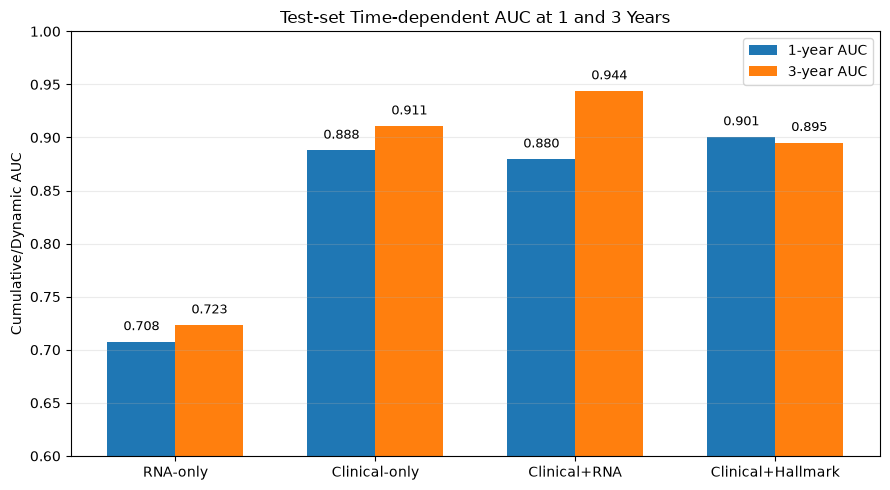

Saved: ..\reports\figures\fig2_time_dependent_auc.png


In [3]:
# ============================================================
# Figure 2 — 1-year and 3-year Time-dependent AUC
# ============================================================

auc_df = pd.read_csv(
    processed_dir / "test_discrimination_metrics.csv"
)

model_order = [
    "RNA-only",
    "Clinical-only",
    "Clinical+RNA",
    "Clinical+Hallmark",
]

auc_df = (
    auc_df
    .set_index("model")
    .loc[model_order]
    .reset_index()
)

x = np.arange(len(model_order))
width = 0.34

fig, ax = plt.subplots(
    figsize=(9, 5)
)

bars_1y = ax.bar(
    x - width / 2,
    auc_df["auc_1year"],
    width,
    label="1-year AUC"
)

bars_3y = ax.bar(
    x + width / 2,
    auc_df["auc_3year"],
    width,
    label="3-year AUC"
)

ax.set_xticks(x)
ax.set_xticklabels(model_order)

ax.set_ylabel(
    "Cumulative/Dynamic AUC"
)

ax.set_title(
    "Test-set Time-dependent AUC at 1 and 3 Years"
)

ax.set_ylim(
    0.6,
    1.0
)

ax.legend()

ax.grid(
    axis="y",
    alpha=0.25
)

# 값 표시
for bars in [bars_1y, bars_3y]:
    for bar in bars:
        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.008,
            f"{height:.3f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

plt.tight_layout()

figure_path = (
    figure_dir
    / "fig2_time_dependent_auc.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", figure_path)

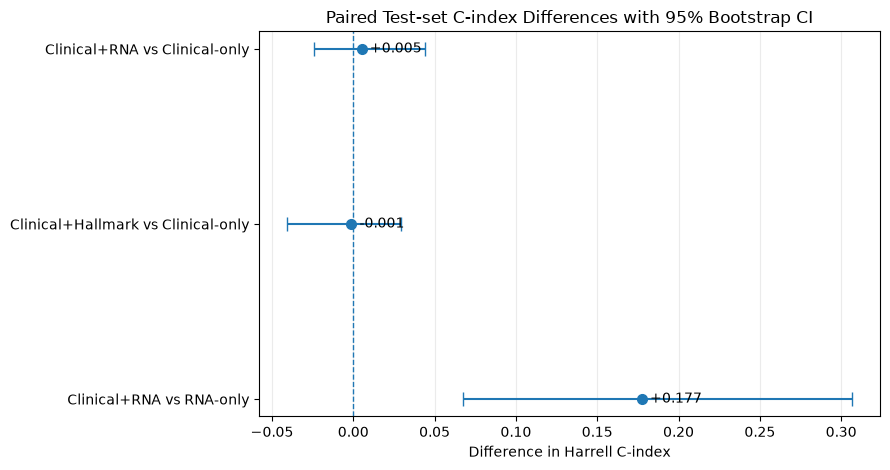

Saved: ..\reports\figures\fig3_paired_cindex_difference_ci.png


In [4]:
# ============================================================
# Figure 3 — Paired C-index difference with 95% Bootstrap CI
# ============================================================

diff_df = pd.read_csv(
    processed_dir / "test_harrell_c_difference_ci.csv"
)

# 보기 좋은 이름
label_map = {
    "Clinical+RNA - Clinical-only":
        "Clinical+RNA vs Clinical-only",

    "Clinical+Hallmark - Clinical-only":
        "Clinical+Hallmark vs Clinical-only",

    "Clinical+RNA - RNA-only":
        "Clinical+RNA vs RNA-only",
}

diff_df["label"] = (
    diff_df["comparison"]
    .map(label_map)
)

delta = (
    diff_df["observed_difference"]
    .to_numpy()
)

lower_error = (
    delta
    - diff_df["ci_95_lower"].to_numpy()
)

upper_error = (
    diff_df["ci_95_upper"].to_numpy()
    - delta
)

y = np.arange(
    len(diff_df)
)

fig, ax = plt.subplots(
    figsize=(9, 4.8)
)

ax.errorbar(
    delta,
    y,
    xerr=np.vstack([
        lower_error,
        upper_error
    ]),
    fmt="o",
    markersize=7,
    capsize=5
)

# 차이가 없다는 기준선
ax.axvline(
    0,
    linestyle="--",
    linewidth=1
)

ax.set_yticks(y)

ax.set_yticklabels(
    diff_df["label"]
)

ax.set_xlabel(
    "Difference in Harrell C-index"
)

ax.set_title(
    "Paired Test-set C-index Differences with 95% Bootstrap CI"
)

ax.grid(
    axis="x",
    alpha=0.25
)

# 관측 차이 숫자 표시
for i, value in enumerate(delta):

    ax.text(
        value + 0.005,
        i,
        f"{value:+.3f}",
        va="center"
    )

ax.invert_yaxis()

plt.tight_layout()

figure_path = (
    figure_dir
    / "fig3_paired_cindex_difference_ci.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    figure_path
)

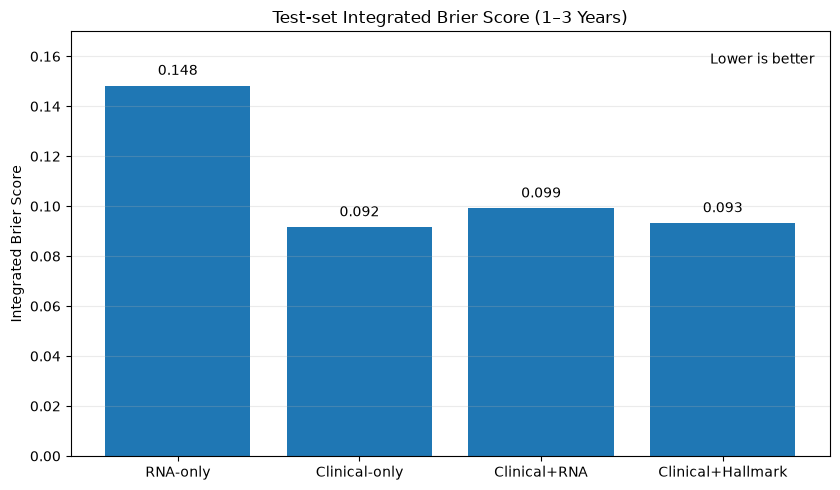

Saved: ..\reports\figures\fig4_integrated_brier_score.png


In [5]:
# ============================================================
# Figure 4 — Integrated Brier Score (1–3 years)
# Lower is better
# ============================================================

brier_df = pd.read_csv(
    processed_dir / "test_brier_ibs_metrics.csv"
)

model_order = [
    "RNA-only",
    "Clinical-only",
    "Clinical+RNA",
    "Clinical+Hallmark",
]

brier_df = (
    brier_df
    .set_index("model")
    .loc[model_order]
    .reset_index()
)

x = np.arange(len(model_order))
ibs = brier_df["ibs_1to3year"].to_numpy()

fig, ax = plt.subplots(
    figsize=(8.5, 5)
)

bars = ax.bar(
    x,
    ibs
)

ax.set_xticks(x)
ax.set_xticklabels(model_order)

ax.set_ylabel(
    "Integrated Brier Score"
)

ax.set_title(
    "Test-set Integrated Brier Score (1–3 Years)"
)

ax.set_ylim(
    0,
    0.17
)

ax.grid(
    axis="y",
    alpha=0.25
)

# 값 표시
for bar, value in zip(bars, ibs):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.003,
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )

# lower is better 안내
ax.text(
    0.98,
    0.95,
    "Lower is better",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=10
)

plt.tight_layout()

figure_path = (
    figure_dir
    / "fig4_integrated_brier_score.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", figure_path)